# Comparativa de Modelos de Regresión: LS, Ridge, ML y MAP

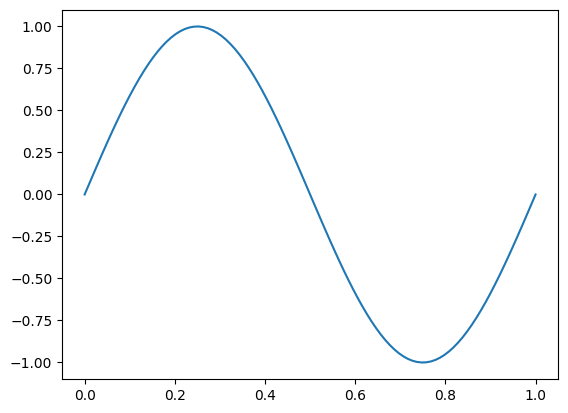

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

N=100
x=np.linspace(0,1,N)
x=x.reshape(-1,1)
y=np.sin(2*np.pi*x)
plt.plot(x,y)
plt.show()

from sklearn.model_selection import train_test_split

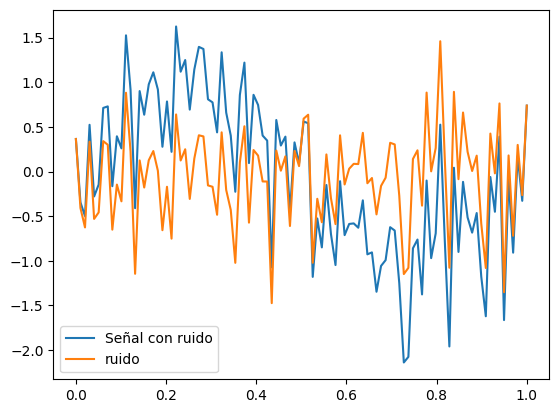

In [ ]:
def snt_db(y_t,snr_db):
  Ps=np.mean(y_t**2)
  Pn=Ps*(10**(-snr_db/10))
  n_o=np.random.normal(0,np.sqrt(Pn),y_t.shape)
  return y_t+n_o,n_o,Pn

# Código de prueba fuera de la función
t,n_o,sigma2=snt_db(y,3)
plt.plot(x,t, label="Señal con ruido")
plt.plot(x,n_o,label="ruido")
plt.legend()
plt.show()

In [ ]:
def Phi_f(x,Q):
  x=np.asarray(x.reshape(-1,1)) # Corregido np,asarray -> np.asarray
  return np.column_stack([x**q for q in range(Q)])
phi=Phi_f(x,10)

def solve(phi,y,l=0): # Añadido el parámetro 'l' con valor por defecto
  return np.linalg.pinv(phi.T@phi+l*np.eye(phi.shape[1]))@phi.T@y # Agregado @phi.T@y para resolver los pesos w

w=solve(phi,x,0) # Cambiado 'x' por 'y' para resolver respecto a las etiquetas

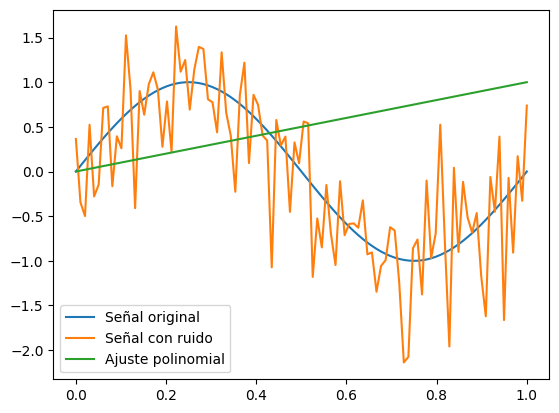

In [ ]:
plt.plot(x,y,label="Señal original")
plt.plot(x,t,label="Señal con ruido")
plt.plot(x,phi@w,label="Ajuste polinomial")
plt.legend()
plt.show()

# Análisis Comparativo de Técnicas de Estimación: LS, Ridge, ML y MAP

En esta sección, se codifican, evalúan y contrastan de forma gráfica cuatro estrategias básicas para estimar parámetros en una regresión polinómica.

---

## 1. Resumen de Variables y Parámetros

| Variable | Tipo / Valor | Descripción |
| :--- | :--- | :--- |
| `x` | Vector $N \times 1$ | Valores de entrada o dominio. |
| `y` | Vector $N \times 1$ | Curva teórica sin perturbaciones. |
| `t` | Vector $N \times 1$ | Datos observados con ruido incorporado ($t = y + \epsilon$). |
| `phi` | Matriz $N \times Q$ | Matriz de diseño ($\boldsymbol{\Phi}$) derivada de $x$. |
| `l` | Escalar ($\ge 0$) | Parámetro de regularización ($\lambda$) usado en la función `solve`. |
| `l_ridge` | Escalar ($0.5$) | Peso de la penalización $L_2$ para el método Ridge. |
| `sigma2` | Escalar ($\sigma^2$) | Varianza del ruido gaussiano añadido a los datos. |
| `sigma_prior2` | Escalar ($0.1$) | Varianza previa establecida para la distribución de pesos. |
| `l_map` | Escalar ($\frac{\sigma^2}{\sigma_{\text{prior}}^2}$) | Nivel de regularización calculado de manera analítica para el MAP. |
| `w_ls`, `w_ridge`, `w_ml`, `w_map` | Vectores $Q \times 1$ | Pesos (coeficientes) resultantes para cada algoritmo. |
| `y_ls`, `y_ridge`, `y_ml`, `y_map` | Vectores $N \times 1$ | Valores estimados por cada técnica ($\hat{y} = \boldsymbol{\Phi}\mathbf{w}$). |

---

## 2. Descripción de las Técnicas Empleadas

### 1. Mínimos Cuadrados Estándar (LS)
* **Configuración:** $l = 0$
* **Detalle:** Busca reducir al mínimo la suma de errores cuadráticos entre los datos empíricos y la predicción. Al no limitar el tamaño de los pesos, es muy susceptible al sobreajuste (*overfitting*) en modelos complejos.

### 2. Regresión Ridge (Mínimos Cuadrados Regularizados)
* **Configuración:** $l_{\text{ridge}} = 0.5$
* **Detalle:** Incorpora un término de castigo $L_2$ proporcional a la magnitud de los coeficientes ($\frac{\lambda}{2} \Vert{}\mathbf{w}\Vert{}^2$). Esto restringe la excesiva flexibilidad del modelo, logrando disminuir la varianza.

### 3. Estimación por Máxima Verosimilitud (ML)
* **Configuración:** $l = 0$
* **Detalle:** Parte del supuesto de que el ruido sigue una distribución normal. Bajo este esquema matemático, el resultado coincide exactamente con el obtenido por Mínimos Cuadrados ($w_{\text{ML}} = w_{\text{LS}}$).

### 4. Estimación Máximo A Posteriori (MAP)
* **Configuración:** $l_{\text{map}} = \frac{\sigma^2}{\sigma_{\text{prior}}^2}$
* **Detalle:** Integra la probabilidad de los datos con una creencia previa (prior) de tipo gaussiano sobre los coeficientes $\mathcal{N}(\mathbf{0}, \sigma_{\text{prior}}^2 \mathbf{I})$. En la práctica, se traduce en una regresión Ridge donde el hiperparámetro de penalización surge directamente del cociente entre la varianza del ruido y la del prior.

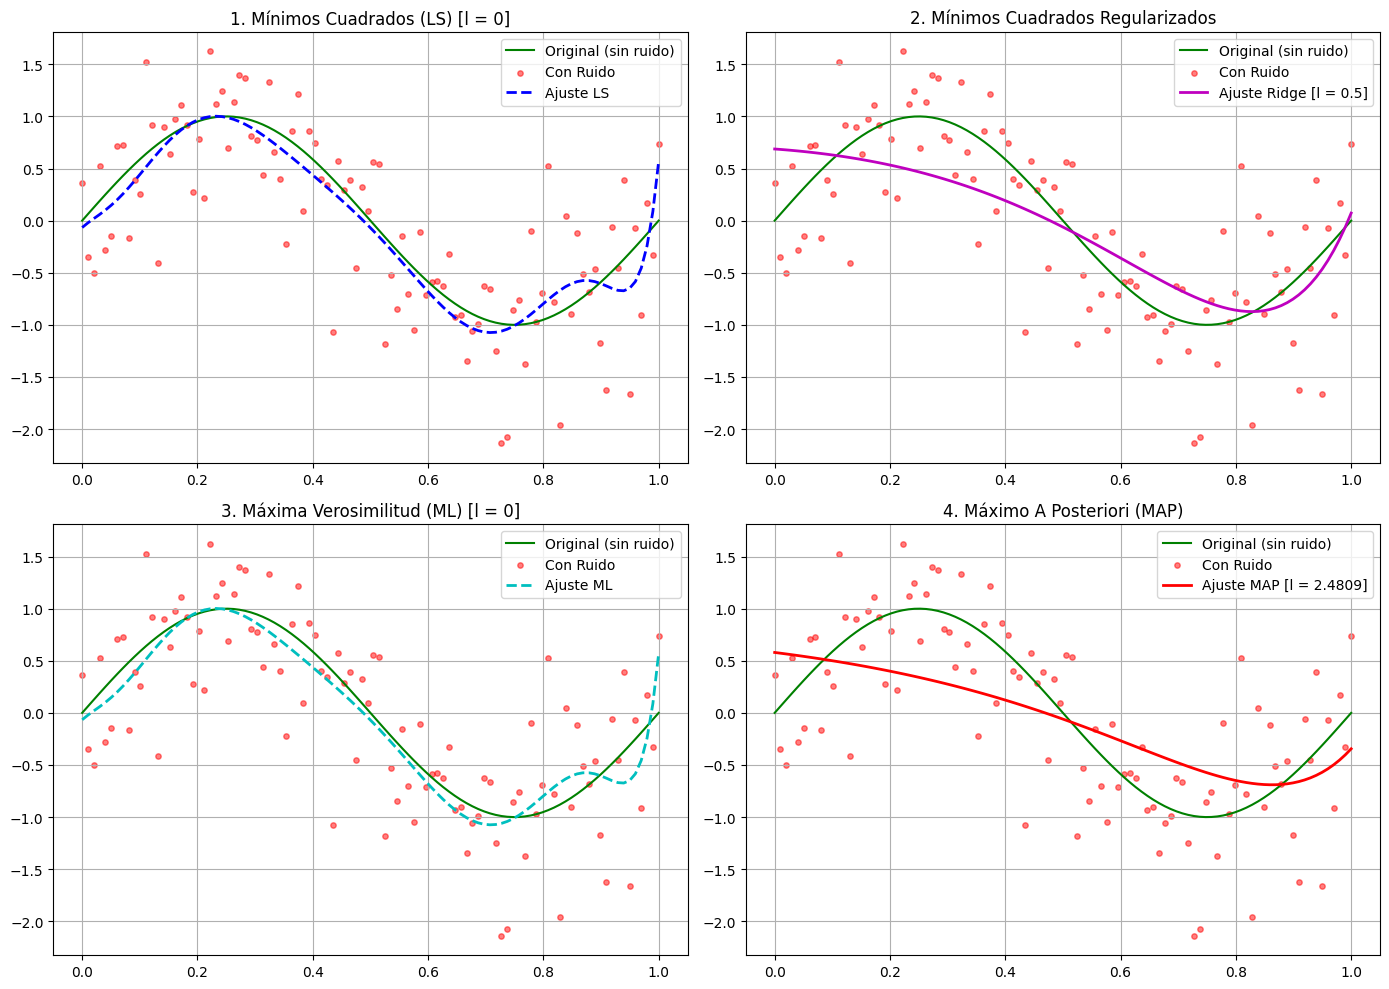

In [ ]:
# 1. Mínimos Cuadrados (LS)
w_ls = solve(phi, t, l=0)
y_ls = phi @ w_ls

# 2. Mínimos Cuadrados Regularizados (Ridge)
l_ridge = 0.5
w_ridge = solve(phi, t, l=l_ridge)
y_ridge = phi @ w_ridge

# 3. Máxima Verosimilitud (ML)
# Coincide numéricamente con LS cuando el ruido es Gaussiano
w_ml = solve(phi, t, l=0)s
y_ml = phi @ w_ml

# 4. Máximo A Posteriori (MAP)
# Lambda se define teóricamente como la razón entre la varianza del ruido (sigma2) y el prior de los pesos (sigma_prior2)
sigma_prior2 = 0.1
l_map = sigma2 / sigma_prior2
w_map = solve(phi, t, l=l_map)
y_map = phi @ w_map

# --- Graficación de los 4 casos ---
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: Mínimos Cuadrados
axs[0, 0].plot(x, y, 'g-', label="Original (sin ruido)")
axs[0, 0].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[0, 0].plot(x, y_ls, 'b--', linewidth=2, label="Ajuste LS")
axs[0, 0].set_title("1. Mínimos Cuadrados (LS) [l = 0]")
axs[0, 0].legend()
axs[0, 0].grid(True)

# Gráfico 2: Mínimos Cuadrados Regularizados
axs[0, 1].plot(x, y, 'g-', label="Original (sin ruido)")
axs[0, 1].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[0, 1].plot(x, y_ridge, 'm-', linewidth=2, label=f"Ajuste Ridge [l = {l_ridge}]")
axs[0, 1].set_title("2. Mínimos Cuadrados Regularizados")
axs[0, 1].legend()
axs[0, 1].grid(True)

# Gráfico 3: Máxima Verosimilitud
axs[1, 0].plot(x, y, 'g-', label="Original (sin ruido)")
axs[1, 0].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[1, 0].plot(x, y_ml, 'c--', linewidth=2, label="Ajuste ML")
axs[1, 0].set_title("3. Máxima Verosimilitud (ML) [l = 0]")
axs[1, 0].legend()
axs[1, 0].grid(True)

# Gráfico 4: Máximo A Posteriori
axs[1, 1].plot(x, y, 'g-', label="Original (sin ruido)")
axs[1, 1].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[1, 1].plot(x, y_map, 'r-', linewidth=2, label=f"Ajuste MAP [l = {l_map:.4f}]")
axs[1, 1].set_title("4. Máximo A Posteriori (MAP)")
axs[1, 1].legend()
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()

# Análisis Visual y Evaluación de los Algoritmos de Regresión

En esta parte del cuaderno se crean datos artificiales, se ensambla la base polinómica, se calculan los coeficientes para los distintos algoritmos (LS, Ridge, ML y MAP) y se exponen los resultados mediante una cuadrícula de gráficos de 2x2.

---

## 1. Definición de Parámetros Clave

| Elemento | Valor asignado | Propósito |
| :--- | :--- | :--- |
| `np.random.seed` | `42` | Fija la semilla para asegurar que los resultados sean reproducibles en futuras ejecuciones. |
| `x` | `np.linspace(0, 1, 100)` | Rango de valores base, conformado por $100$ puntos espaciados uniformemente en $[0, 1]$. |
| `y` | `np.sin(2 * np.pi * x)` | Curva ideal basada en una onda seno. |
| `sigma2` | `0.25**2` ($0.0625$) | Varianza teórica asignada al ruido ($\sigma^2$). |
| `noise` | $\mathcal{N}(0, \sigma^2)$ | Ruido blanco gaussiano con una desviación de $\sigma = 0.25$. |
| `t` | `y + noise` | Etiquetas objetivo finales generadas sumando el ruido a la señal pura. |
| `Q` | `10` | Nivel de complejidad (grado máximo) del polinomio utilizado. |
| `phi` | `Phi_f(x, Q)` | Matriz proyectada $\boldsymbol{\Phi}$ con dimensiones de $100 \times 10$. |
| `l_ridge` | `0.5` | Constante de regularización $L_2$ estática asignada a la regresión Ridge. |
| `sigma_prior2` | `0.1` | Nivel de dispersión previa $\sigma_{\text{prior}}^2$ asumida para los pesos. |
| `l_map` | `sigma2 / sigma_prior2` | Valor deducido analíticamente para el parámetro del modelo MAP ($0.625$). |

---

## 2. Secuencia de Ejecución

1. **Creación del Conjunto de Datos:** Se simula un entorno real corrompiendo una curva senoidal perfecta con ruido aleatorio.
2. **Construcción de Características:** Se expande la variable $x$ a múltiples dimensiones mediante una base polinómica de grado $10$.
3. **Determinación de los Coeficientes ($\mathbf{w}$):**
   * **LS:** Realiza la estimación sin ninguna penalidad ($l = 0$).
   * **Ridge:** Aplica una restricción moderada a los pesos ($l_{\text{ridge}} = 0.5$).
   * **ML:** Al asumir distribución normal en el ruido sin un prior, su respuesta iguala a LS ($l = 0$).
   * **MAP:** Emplea el ratio de varianzas para calcular su propio término restrictivo $l_{\text{map}}$.
4. **Generación de Gráficos:** Se visualizan 4 subgráficos comparando la señal original (línea verde), las muestras ruidosas (puntos rojos) y la curva trazada por el modelo.

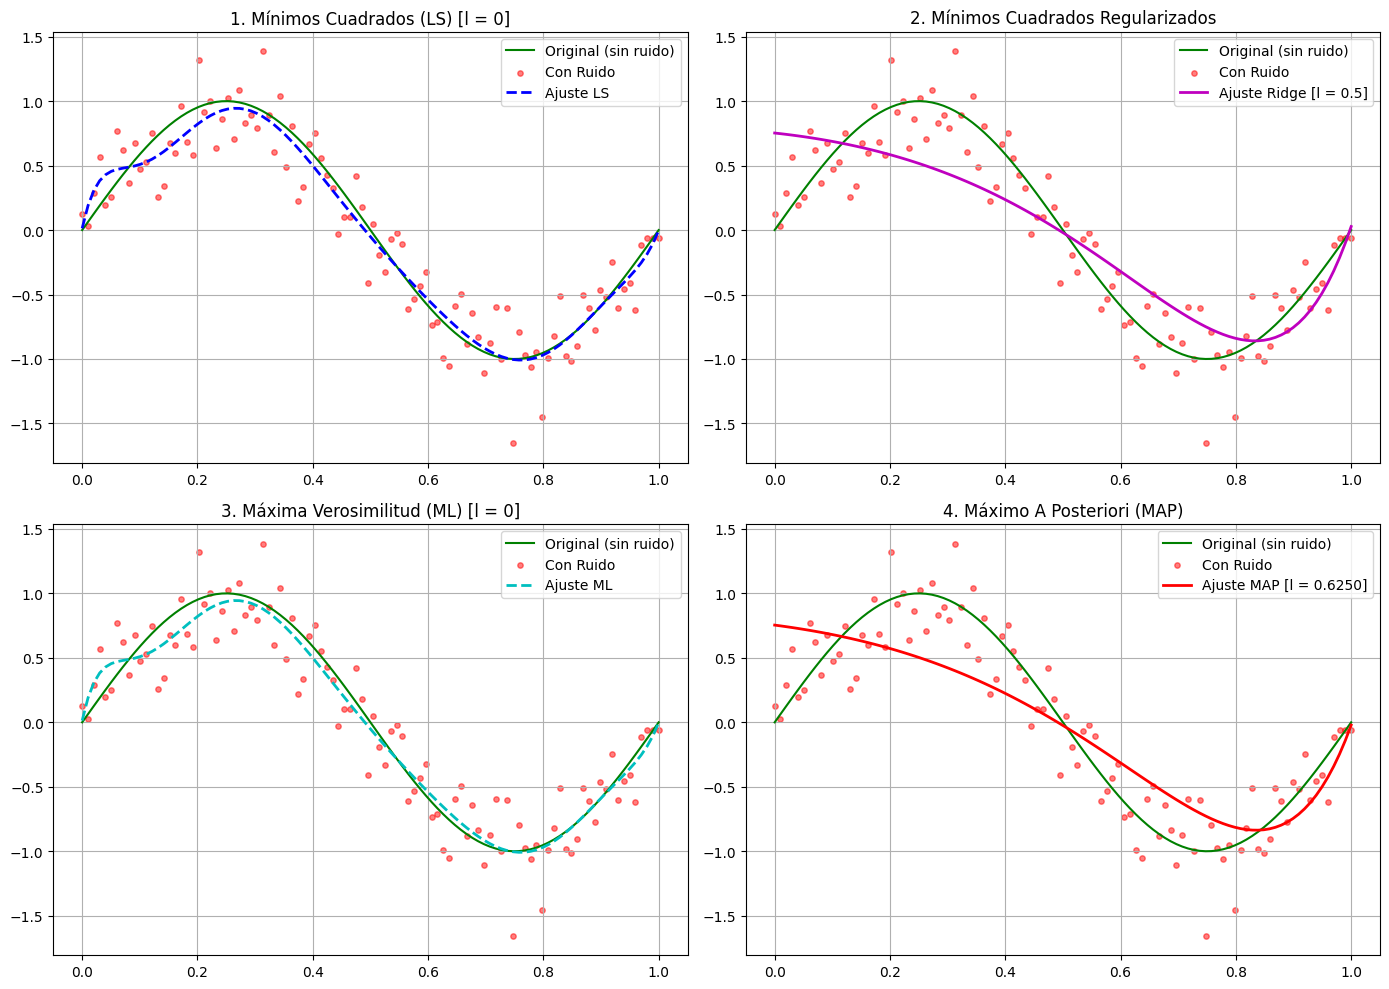

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. GENERACIÓN DE DATOS Y MATRIZ DE DISEÑO
# ==========================================
np.random.seed(42)

# Datos de entrada y función original
x = np.linspace(0, 1, 100)
y = np.sin(2 * np.pi * x)

# Ruido gaussiano aditivo
sigma2 = 0.25**2
noise = np.random.normal(0, np.sqrt(sigma2), size=x.shape)
t = y + noise

# Evaluación de la matriz de diseño (grado Q = 10)
Q = 10
phi = Phi_f(x, Q)

# ==========================================
# 2. CÁLCULO DE MODELOS (LS, RIDGE, ML, MAP)
# ==========================================

# 1. Mínimos Cuadrados (LS)
w_ls = solve(phi, t, l=0)
y_ls = phi @ w_ls

# 2. Mínimos Cuadrados Regularizados (Ridge)
l_ridge = 0.5
w_ridge = solve(phi, t, l=l_ridge)
y_ridge = phi @ w_ridge

# 3. Máxima Verosimilitud (ML)
w_ml = solve(phi, t, l=0)
y_ml = phi @ w_ml

# 4. Máximo A Posteriori (MAP)
sigma_prior2 = 0.1
l_map = sigma2 / sigma_prior2
w_map = solve(phi, t, l=l_map)
y_map = phi @ w_map

# ==========================================
# 3. GRAFICACIÓN
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Subplot 1: Mínimos Cuadrados
axs[0, 0].plot(x, y, 'g-', label="Original (sin ruido)")
axs[0, 0].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[0, 0].plot(x, y_ls, 'b--', linewidth=2, label="Ajuste LS")
axs[0, 0].set_title("1. Mínimos Cuadrados (LS) [l = 0]")
axs[0, 0].legend()
axs[0, 0].grid(True)

# Subplot 2: Mínimos Cuadrados Regularizados
axs[0, 1].plot(x, y, 'g-', label="Original (sin ruido)")
axs[0, 1].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[0, 1].plot(x, y_ridge, 'm-', linewidth=2, label=f"Ajuste Ridge [l = {l_ridge}]")
axs[0, 1].set_title("2. Mínimos Cuadrados Regularizados")
axs[0, 1].legend()
axs[0, 1].grid(True)

# Subplot 3: Máxima Verosimilitud
axs[1, 0].plot(x, y, 'g-', label="Original (sin ruido)")
axs[1, 0].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[1, 0].plot(x, y_ml, 'c--', linewidth=2, label="Ajuste ML")
axs[1, 0].set_title("3. Máxima Verosimilitud (ML) [l = 0]")
axs[1, 0].legend()
axs[1, 0].grid(True)

# Subplot 4: Máximo A Posteriori
axs[1, 1].plot(x, y, 'g-', label="Original (sin ruido)")
axs[1, 1].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[1, 1].plot(x, y_map, 'r-', linewidth=2, label=f"Ajuste MAP [l = {l_map:.4f}]")
axs[1, 1].set_title("4. Máximo A Posteriori (MAP)")
axs[1, 1].legend()
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()


# Reevaluación de Modelos Ajustando los Hiperparámetros

En esta sección se vuelven a entrenar y graficar los cuatro modelos, pero esta vez calibrando los niveles de regularización. El objetivo principal es mitigar el problema de *underfitting* (subajuste) que evidenciaban los métodos Ridge y MAP en el escenario anterior.

---

## 1. Resumen de los Nuevos Parámetros

| Elemento | Configuración | Función |
| :--- | :--- | :--- |
| `np.random.seed` | `42` | Semilla para garantizar que las muestras sintéticas sean idénticas. |
| `x` | `np.linspace(0, 1, 100)` | Eje X compuesto por $100$ divisiones equidistantes en el rango $[0, 1]$. |
| `y` | `np.sin(2 * np.pi * x)` | Onda senoidal pura que actúa como *ground truth* (verdad fundamental). |
| `sigma2` | `0.25**2` ($0.0625$) | Nivel de varianza del ruido introducido $\sigma^2$. |
| `noise` | $\mathcal{N}(0, \sigma^2)$ | Perturbación de distribución normal aplicada ($\sigma = 0.25$). |
| `t` | `y + noise` | Datos observados finales sobre los que el algoritmo se entrena. |
| `Q` | `10` | Grado máximo de expansión de la base polinómica. |
| `phi` | `Phi_f(x, Q)` | Matriz de diseño $\boldsymbol{\Phi}$ resultante de tamaño $100 \times 10$. |
| `l_ridge` | `0.01` | **Penalización atenuada:** Al reducir este valor, se le da al modelo mayor grado de libertad. |
| `sigma_prior2` | `1.0` | **Menor certeza a priori:** Subir esta varianza indica que confiamos más en la evidencia empírica que en la creencia inicial de pesos cercanos a cero. |
| `l_map` | `sigma2 / sigma_prior2` | **Nuevo coeficiente MAP:** Cae significativamente a $0.0625$ gracias a los cambios anteriores. |

---

## 2. Impacto de los Cambios y Comportamiento Visual

1. **Mínimos Cuadrados (LS) y Máxima Verosimilitud (ML) [$l = 0$]:** Sus resultados no experimentan cambios ya que su formulación no incluye parámetros de penalización.
2. **Ridge y MAP:** Tras rebajar considerablemente la severidad de la regularización, las funciones ajustadas ganan suficiente flexibilidad para adherirse mucho mejor a la forma senoidal latente de los datos, resolviendo así el aplanamiento excesivo del experimento previo.

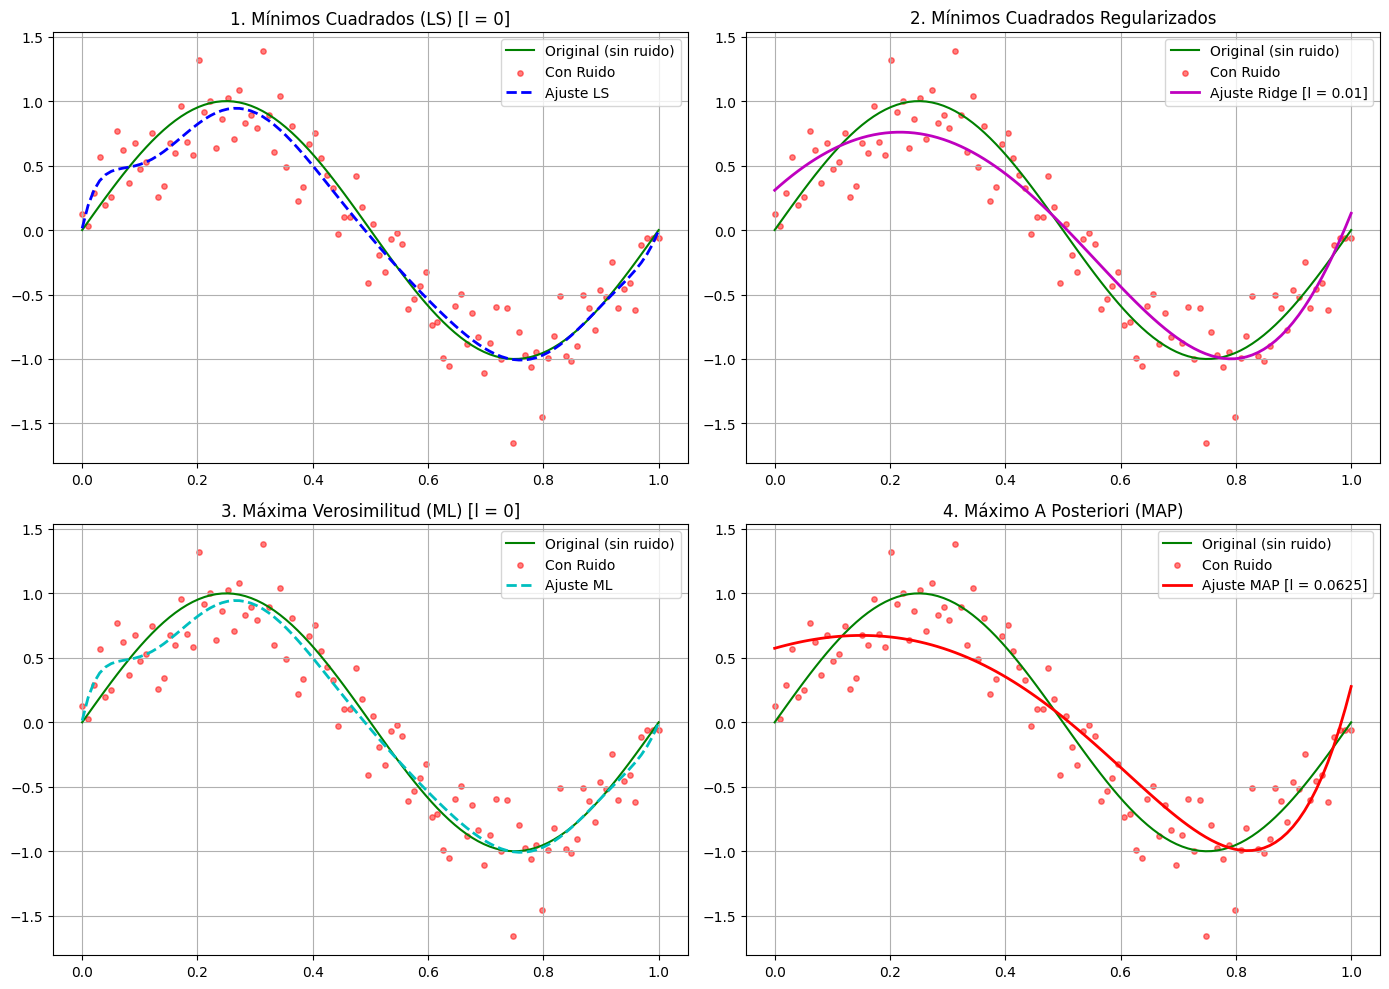

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. GENERACIÓN DE DATOS Y MATRIZ DE DISEÑO
# ==========================================
np.random.seed(42)

# Datos de entrada y función original
x = np.linspace(0, 1, 100)
y = np.sin(2 * np.pi * x)

# Ruido gaussiano aditivo
sigma2 = 0.25**2
noise = np.random.normal(0, np.sqrt(sigma2), size=x.shape)
t = y + noise

# Matriz de diseño (Q = 10)
Q = 10
phi = Phi_f(x, Q)

# ==========================================
# 2. CÁLCULO DE MODELOS CON PARÁMETROS AJUSTADOS
# ==========================================

# 1. Mínimos Cuadrados (LS)
w_ls = solve(phi, t, l=0)
y_ls = phi @ w_ls

# 2. Mínimos Cuadrados Regularizados (Ridge) - l reducido a 0.01
l_ridge = 0.01
w_ridge = solve(phi, t, l=l_ridge)
y_ridge = phi @ w_ridge

# 3. Máxima Verosimilitud (ML)
w_ml = solve(phi, t, l=0)
y_ml = phi @ w_ml

# 4. Máximo A Posteriori (MAP) - sigma_prior2 aumentado a 1.0 (reduce l_map a ~0.0625)
sigma_prior2 = 1.0
l_map = sigma2 / sigma_prior2
w_map = solve(phi, t, l=l_map)
y_map = phi @ w_map

# ==========================================
# 3. GRAFICACIÓN
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Subplot 1: Mínimos Cuadrados
axs[0, 0].plot(x, y, 'g-', label="Original (sin ruido)")
axs[0, 0].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[0, 0].plot(x, y_ls, 'b--', linewidth=2, label="Ajuste LS")
axs[0, 0].set_title("1. Mínimos Cuadrados (LS) [l = 0]")
axs[0, 0].legend()
axs[0, 0].grid(True)

# Subplot 2: Mínimos Cuadrados Regularizados
axs[0, 1].plot(x, y, 'g-', label="Original (sin ruido)")
axs[0, 1].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[0, 1].plot(x, y_ridge, 'm-', linewidth=2, label=f"Ajuste Ridge [l = {l_ridge}]")
axs[0, 1].set_title("2. Mínimos Cuadrados Regularizados")
axs[0, 1].legend()
axs[0, 1].grid(True)

# Subplot 3: Máxima Verosimilitud
axs[1, 0].plot(x, y, 'g-', label="Original (sin ruido)")
axs[1, 0].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[1, 0].plot(x, y_ml, 'c--', linewidth=2, label="Ajuste ML")
axs[1, 0].set_title("3. Máxima Verosimilitud (ML) [l = 0]")
axs[1, 0].legend()
axs[1, 0].grid(True)

# Subplot 4: Máximo A Posteriori
axs[1, 1].plot(x, y, 'g-', label="Original (sin ruido)")
axs[1, 1].scatter(x, t, color='red', alpha=0.5, s=15, label="Con Ruido")
axs[1, 1].plot(x, y_map, 'r-', linewidth=2, label=f"Ajuste MAP [l = {l_map:.4f}]")
axs[1, 1].set_title("4. Máximo A Posteriori (MAP)")
axs[1, 1].legend()
axs[1, 1].grid(True)

plt.tight_layout()
plt.show()
